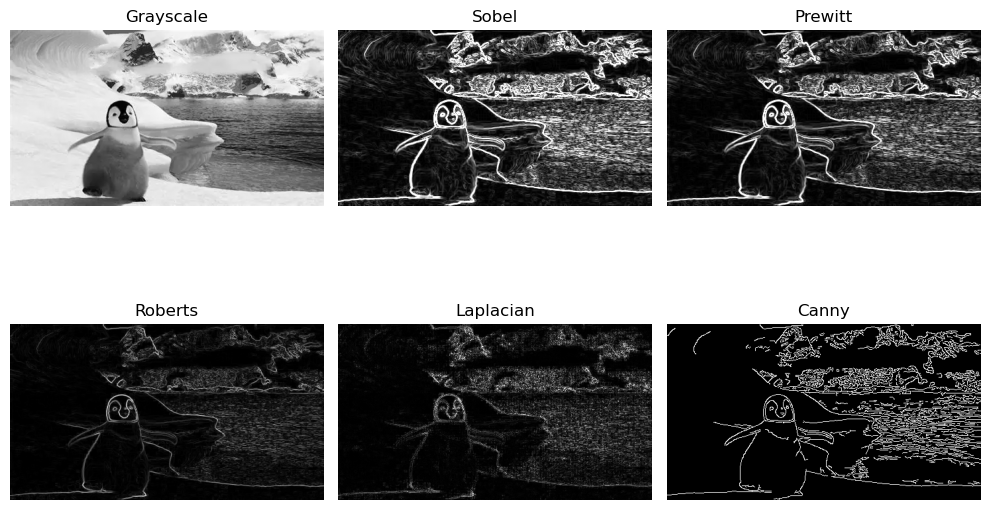

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image
img = cv2.imread("picture.webp")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Sobel operator
sx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sx, sy))

# Prewitt operator
kx = np.array([[-1, 0, 1],
               [-1, 0, 1],
               [-1, 0, 1]])
ky = np.array([[-1, -1, -1],
               [ 0,  0,  0],
               [ 1,  1,  1]])
px = cv2.filter2D(gray, cv2.CV_32F, kx)
py = cv2.filter2D(gray, cv2.CV_32F, ky)
prewitt = cv2.convertScaleAbs(cv2.magnitude(px, py))

# Roberts operator
rx = np.array([[1, 0], [0, -1]])
ry = np.array([[0, 1], [-1, 0]])
gx = cv2.filter2D(gray, cv2.CV_32F, rx)
gy = cv2.filter2D(gray, cv2.CV_32F, ry)
roberts = cv2.convertScaleAbs(cv2.magnitude(gx, gy))

# Laplacian operator
laplacian = cv2.convertScaleAbs(
    cv2.Laplacian(gray, cv2.CV_64F)
)

# Canny edge detector
canny = cv2.Canny(gray, 100, 200)

# Display results
images = [gray, sobel, prewitt, roberts, laplacian, canny]
titles = ["Grayscale", "Sobel", "Prewitt",
          "Roberts", "Laplacian", "Canny"]

plt.figure(figsize=(10, 7))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()